# Stage E — Histogram Normalization and Spatial Encoding

Report: one summary table and one figure. Read-only analysis of saved metrics; no model training.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [
    Path('metrics.csv'),
    Path('results/part1/stageE/metrics.csv'),
    Path('results/stageE/metrics.csv'),
    Path('stageE/metrics.csv'),
]
csv_path = next((p for p in candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError('Coloca o notebook em stageE ou abre-o na raiz do projeto.')
df = pd.read_csv(csv_path)
out = csv_path.parent / 'report_assets'
out.mkdir(parents=True, exist_ok=True)
print(f'{len(df)} experiments | {df.category.nunique()} categories | K={df.k.unique().tolist()}')

45 experiments | 5 categories | K=[128]


In [2]:
layouts = ['global', '2x2', 'pyramid']
norms = ['none', 'l1', 'l2']
names = {'global': 'Global', '2x2': '2×2', 'pyramid': 'Pyramid L2'}
summary = df.groupby(['tiling', 'normalization'], as_index=False).agg(
    dimension=('dimension', 'first'),
    val_map=('val_ap', 'mean'),
    test_map=('test_ap', 'mean'),
)
summary['tiling'] = pd.Categorical(summary['tiling'], categories=layouts, ordered=True)
summary['normalization'] = pd.Categorical(summary['normalization'], categories=norms, ordered=True)
summary = summary.sort_values(['tiling', 'normalization']).reset_index(drop=True)
table = pd.DataFrame({
    'Layout': summary['tiling'].map(names).astype(str),
    'Norm.': summary['normalization'].str.upper().replace({'NONE': 'None'}),
    'Dim.': summary['dimension'],
    'Val. mAP': summary['val_map'],
    'Test mAP': summary['test_map'],
})
display(table.style.format({'Val. mAP': '{:.3f}', 'Test mAP': '{:.3f}'}).hide(axis='index'))
table.to_csv(out / 'stageE_normalization_summary.csv', index=False)

Layout,Norm.,Dim.,Val. mAP,Test mAP
Global,None,128,0.433,0.417
Global,L1,128,0.584,0.527
Global,L2,128,0.601,0.533
2×2,None,512,0.551,0.449
2×2,L1,512,0.599,0.549
2×2,L2,512,0.669,0.573
Pyramid L2,None,2688,0.606,0.539
Pyramid L2,L1,2688,0.615,0.564
Pyramid L2,L2,2688,0.691,0.586


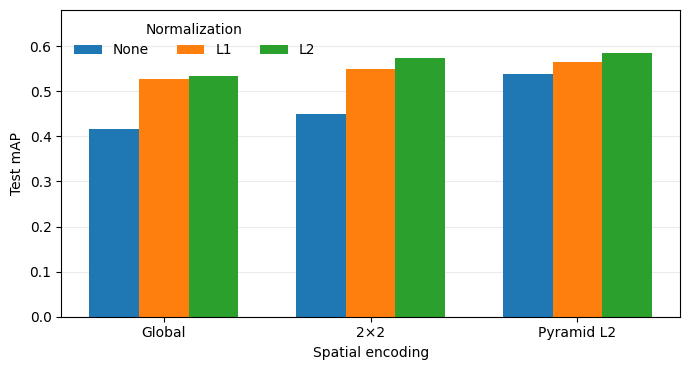

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(layouts))
width = 0.24
for j, norm in enumerate(norms):
    values = [summary.loc[
        (summary.tiling == layout) & (summary.normalization == norm), 'test_map'
    ].iloc[0] for layout in layouts]
    ax.bar(x + (j-1)*width, values, width, label=norm.upper() if norm!='none' else 'None')
ax.set_xticks(x, [names[l] for l in layouts])
ax.set_ylim(0, 0.68)
ax.set_xlabel('Spatial encoding')
ax.set_ylabel('Test mAP')
ax.legend(title='Normalization', frameon=False, ncol=3, loc='upper left')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(out / 'stageE_test_map.png', dpi=250, bbox_inches='tight')
plt.show()